1. Install everything
 - Open Jupyter Notebook and create a new Python notebook.
 - CELL 1 — INSTALL LIBRARIES

In [ ]:
%pip install -U langchain langchain-openai python-dotenv langgraph ipykernel

In [1]:
import langchain
import langgraph
import langchain_openai

print("LangChain installed successfully!")
print("LangGraph installed successfully!")

LangChain installed successfully!
LangGraph installed successfully!


2. Start with ordinary Python
Before using ai, udnerstand the business problem

In [2]:
customer = {
    "name": "Rahul",
    "product": "Laptop",
    "amount": 65000,
    "complaint": "My laptop arrived damaged"
}

print(customer)

{'name': 'Rahul', 'product': 'Laptop', 'amount': 65000, 'complaint': 'My laptop arrived damaged'}


Normal Python function

In [3]:
def refund_check(amount):

    if amount <= 10000:
        return "Automatic refund eligible"

    return "Manager review required"


print(refund_check(65000))

Manager review required


# Now We will introduce langChain

LangChain helps conenct prompts, langaugae models, and other componets

In [5]:
import os
from getpass import getpass

if not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass(
        "Enter OpenAI API key: "
    )

In [6]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model="gpt-4.1-mini",
    temperature=0
)

response = llm.invoke(
    "Explain customer support in one simple sentence."
)

print(response.content)

Customer support is helping customers solve problems and answer questions about a product or service.


In [7]:
from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_template(
    """
    You are a helpful customer support assistant.

    Customer complaint: {complaint}

    Explain the problem in simple language.
    Suggest one appropriate next action.
    Do not promise a refund.
    """
)

In [8]:
chain = prompt | llm

result = chain.invoke({
    "complaint": "My laptop arrived damaged"
})

print(result.content)

I'm sorry to hear that your laptop arrived damaged. This means that something on your laptop is broken or not working properly when you first received it. 

The best next step is to contact the seller or the store where you bought the laptop and let them know about the damage. They can guide you on how to get it repaired or replaced.


In [9]:
from typing import TypedDict

class SupportState(TypedDict):
    complaint: str
    amount: int
    analysis: str
    decision: str

In [10]:
def analyze_node(state: SupportState):

    result = chain.invoke({
        "complaint": state["complaint"]
    })

    return {
        "analysis": result.content
    }

In [11]:
def refund_node(state: SupportState):

    if state["amount"] <= 10000:
        decision = "Automatic refund eligible"
    else:
        decision = "Manager review required"

    return {
        "decision": decision
    }

In [12]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(SupportState)

builder.add_node("analyze", analyze_node)
builder.add_node("refund", refund_node)

builder.add_edge(START, "analyze")
builder.add_edge("analyze", "refund")
builder.add_edge("refund", END)

graph = builder.compile()

In [13]:
result = graph.invoke({
    "complaint": "My laptop arrived damaged",
    "amount": 65000,
    "analysis": "",
    "decision": ""
})

print("AI Analysis:", result["analysis"])
print("Decision:", result["decision"])

AI Analysis: I'm sorry to hear that your laptop arrived damaged. This means that the laptop has some kind of physical problem or defect when you received it. The best next step is to contact the customer support team or the seller directly to report the damage and discuss how they can help you with a replacement or repair.
Decision: Manager review required


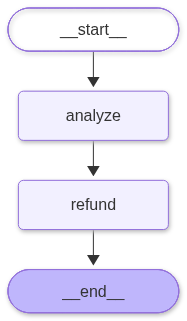

In [14]:
from IPython.display import display, Image

display(
    Image(graph.get_graph().draw_mermaid_png())
)

In [16]:
def choose_route(state: SupportState):

    if state["amount"] <= 10000:
        return "automatic"

    return "manager"

In [17]:
def automatic_refund(state: SupportState):

    return {
        "decision": "Automatic refund eligible"
    }


def manager_review(state: SupportState):

    return {
        "decision": "Manager review required"
    }

In [18]:
smart_builder = StateGraph(SupportState)

smart_builder.add_node("analyze", analyze_node)
smart_builder.add_node("automatic", automatic_refund)
smart_builder.add_node("manager", manager_review)

smart_builder.add_edge(START, "analyze")

smart_builder.add_conditional_edges(
    "analyze",
    choose_route,
    {
        "automatic": "automatic",
        "manager": "manager"
    }
)

smart_builder.add_edge("automatic", END)
smart_builder.add_edge("manager", END)

smart_graph = smart_builder.compile()

In [19]:
cases = [
    {
        "complaint": "My headphones are damaged",
        "amount": 2500,
        "analysis": "",
        "decision": ""
    },
    {
        "complaint": "My laptop arrived damaged",
        "amount": 65000,
        "analysis": "",
        "decision": ""
    }
]

for case in cases:

    result = smart_graph.invoke(case)

    print("Complaint:", case["complaint"])
    print("Decision:", result["decision"])
    print("-" * 40)

Complaint: My headphones are damaged
Decision: Automatic refund eligible
----------------------------------------
Complaint: My laptop arrived damaged
Decision: Manager review required
----------------------------------------


In [20]:
class OrderState(TypedDict):
    order_id: str
    attempts: int
    message: str

In [21]:
def check_order(state: OrderState):

    if state["order_id"]:
        return {"message": "Order ID verified"}

    return {"message": "Order ID missing"}


def request_order(state: OrderState):

    return {
        "attempts": state["attempts"] + 1,
        "message": "Requesting order ID"
    }


def route_order(state: OrderState):

    if state["order_id"]:
        return "done"

    if state["attempts"] >= 2:
        return "done"

    return "retry"

In [22]:
cycle_builder = StateGraph(OrderState)

cycle_builder.add_node("check", check_order)
cycle_builder.add_node("request", request_order)

cycle_builder.add_edge(START, "check")

cycle_builder.add_conditional_edges(
    "check",
    route_order,
    {
        "retry": "request",
        "done": END
    }
)

cycle_builder.add_edge("request", "check")

cycle_graph = cycle_builder.compile()

In [23]:
result = cycle_graph.invoke({
    "order_id": "",
    "attempts": 0,
    "message": ""
})

print(result)

{'order_id': '', 'attempts': 2, 'message': 'Order ID missing'}
